# **Lab 2 – Tidying, Cleaning, Imputation, and Outlier Detection**

## Machine Learning Programming

This assignment continues the work started in **`week5Lab.ipynb`**.  
Open this notebook and complete the activities **in this notebook**, preserving the section order and the overall structure.

The purpose of this lab is to practice the data-preprocessing work that normally takes place before machine learning: reshaping data, cleaning inconsistent values, handling missing data, detecting outliers, visualizing results, and explaining the decisions you make.

## **Assignment Overview**

### Purpose
By the end of this lab, you should be able to take several imperfect datasets and make them more suitable for analysis and later machine-learning work.

### Learning Outcomes
You will practice how to:

- inspect the shape, columns, data types, and quality of a dataset;
- distinguish **wide** and **long/tidy** data;
- reshape data with `pd.melt()` or `DataFrame.melt()`;
- clean strings using Pandas string methods;
- identify, quantify, drop, and impute missing values;
- compare mean, median, mode, and `SimpleImputer` approaches;
- identify outliers visually with box plots and scatter plots;
- identify outliers statistically using **Z-Scores** and **IQR**;
- justify preprocessing decisions using evidence from the data;
- document a reproducible Python data-processing workflow.

### Estimated Completion Time
Approximately **2.5–3.5 hours**, depending on your Python experience.

## **Submission and Project Structure**

Keep the project organized so another person can reproduce your work.

Recommended structure:

```text
project/
├── week5Lab.ipynb
├── README.md
├── requirements.txt
├── .gitignore
└── data/
    ├── pew-raw.csv
    ├── billboard.csv
    ├── cars.csv
    └── diabetes.csv
```

A clearly named equivalent data folder such as `CSVs/` or `datasets/` is also acceptable if all notebook paths are updated consistently.

### Required submission artifacts

- `week5Lab.ipynb` containing **all four completed sections**
- `README.md` with at least 1–2 meaningful sentences describing the lab and how to run it
- `requirements.txt` containing the packages required to reproduce the environment
- `.gitignore`
- all required data files inside a clearly named data folder

**Important:** Use relative paths such as `./data/cars.csv`. Do not use absolute paths from your own computer.

**Environment practice:** Use `requirements.txt` to define the environment. Do not add `!pip install ...` cells to the notebook when a requirements file is provided.

## **Before You Begin**

Use the following libraries where appropriate:

- `pandas`
- `numpy`
- `matplotlib`
- `seaborn`
- `scikit-learn`

Run the import cell below before beginning the exercises.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.impute import SimpleImputer

# Optional display settings
pd.set_option("display.max_columns", None)

## **General Expectations**

For every section:

1. Write the required Python code.
2. Display enough output to demonstrate that the code works.
3. Add short Markdown explanations in your own words.
4. Label plots clearly with a title and axis labels.
5. Explain what the output means instead of only producing it.
6. Preserve the required section headings so the notebook is easy to follow.
7. Before submitting, restart the kernel and use **Run All** to confirm the notebook executes from beginning to end.

## Replicability Check

I tested the project in a separate clean Conda environment using Python 3.11.

During the first test, the original `requirements.txt` created with `pip freeze` contained local Conda build paths such as `file:///C:/...`. These paths were not portable and caused package installation to fail in the new environment.

I fixed this by regenerating `requirements.txt` using:

`python -m pip list --format=freeze > requirements.txt`

This produced portable `package==version` entries.

I then created a new `lab2_test` environment, installed the dependencies from `requirements.txt`, registered the environment as a Jupyter kernel, and executed the complete notebook from top to bottom using `nbconvert`.

The final replicability test completed successfully. This confirmed that the notebook can run in a clean environment using the submitted dependencies and relative dataset paths.

# **Section 1 – PEW Research Dataset**

## **Learning Topic: Data Tidying and Reshaping**

A dataset is commonly described as **tidy** when:

1. each variable forms a column;
2. each observation forms a row; and
3. each type of observational unit forms a table.

The PEW dataset represents counts for religions across income ranges. In its original form, income values appear as column headings. You will reshape the dataset from **wide** format to **long/tidy** format using `melt()`.

### Required concepts
- dataset inspection
- wide versus long data
- identifier variables
- measured variables
- `pd.melt()` or `DataFrame.melt()`
- visualization after reshaping

## **Getting the PEW Dataset from the Internet**

For this lab, use the small **PEW religion-and-income dataset** commonly used to demonstrate tidy-data principles. This is the dataset whose first column is `religion` and whose remaining columns are income ranges such as `<$10k`, `$10-20k`, and `$20-30k`.

### Recommended method — download in your browser

1. Open the dataset in a browser:
   `https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv`
2. Save the file as **`pew-raw.csv`**.
3. Create a folder named **`data`** in the same project folder as this notebook if it does not already exist.
4. Move `pew-raw.csv` into the `data` folder.
5. Confirm that your project contains:

```text
project/
├── week5Lab.ipynb
└── data/
    └── pew-raw.csv
```

6. Load the local copy with:

```python
df_pew = pd.read_csv("./data/pew-raw.csv")
```

### Optional Python-assisted download

The following is an example only. You may use it once to obtain the dataset, but your submitted analysis should subsequently read the **local copy** from `./data/`.

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv"
df_pew = pd.read_csv(url)
df_pew.to_csv("./data/pew-raw.csv", index=False)
```

### Verify before continuing

After loading the file, check that the dataframe contains a `religion` column and multiple income-range columns. If it does not, stop and verify that you downloaded the correct dataset.

> **Good reproducibility practice:** Do not depend on the Internet every time the notebook runs. Download the dataset once, store it in the project's `data/` folder, commit the permitted data file to your repository, and use a relative path in the notebook.

### **Task 1.1 – Load and Inspect the Dataset**

1. Load the PEW dataset from your data folder.
2. Display its shape.
3. Display its column names.
4. Display several rows using `head()`, `loc`, `iloc`, or `tail()`.
5. Identify the column that should remain the identifier variable.

In [2]:
df_pew = pd.read_csv("./data/pew-raw.csv")

print("Shape of PEW dataset:")
print(df_pew.shape)

print("\nColumn names:")
print(df_pew.columns)

print("\nFirst 5 rows:")
df_pew.head()

Shape of PEW dataset:
(10, 7)

Column names:
Index(['religion', ' <$10k', ' $10-20k', '$20-30k', '$30-40k', ' $40-50k',
       '$50-75k'],
      dtype='str')

First 5 rows:


,religion,<$10k,$10-20k,$20-30k,$30-40k,$40-50k,$50-75k
0,Agnostic,27,34,60,81,76,137
1,Atheist,12,27,37,52,35,70
2,Buddhist,27,21,30,34,33,58
3,Catholic,418,617,732,670,638,1116
4,Dont know/refused,15,14,15,11,10,35


In [3]:
df_pew.columns = df_pew.columns.str.strip()

print("\nCleaned column names:")
print(df_pew.columns)


Cleaned column names:
Index(['religion', '<$10k', '$10-20k', '$20-30k', '$30-40k', '$40-50k',
       '$50-75k'],
      dtype='str')


### **Task 1.2 – Explain the Problem**

In a Markdown cell below, answer:

- What is not tidy about the original PEW dataset?
- Which values are stored in column names?
- Which column should be treated as the identifier (`id_vars`)?

### Explanation

The original PEW dataset is not completely tidy because the income ranges are stored as separate column names. Income should be one variable, but values such as `<$10k`, `$10-20k`, and `$20-30k` are spread across multiple columns.

The values stored in the column names are the different income ranges.

The `religion` column should be used as the identifier (`id_vars`) because it identifies the religion associated with each set of income counts.

### **Task 1.3 – Reshape with `melt()`**

Use either of these valid Pandas forms:

```python
pd.melt(...)
```

or

```python
df.melt(...)
```

Your result should have meaningful names for the new variable and value columns, such as `income` and `count`.

In [4]:
df_pew_tidy = df_pew.melt(
    id_vars="religion",
    var_name="income",
    value_name="count"
)

print("First rows of tidy PEW dataset:")
display(df_pew_tidy.head(10))

print("Original shape:", df_pew.shape)
print("Reshaped shape:", df_pew_tidy.shape)

First rows of tidy PEW dataset:


,religion,income,count
0,Agnostic,<$10k,27
1,Atheist,<$10k,12
2,Buddhist,<$10k,27
3,Catholic,<$10k,418
4,Dont know/refused,<$10k,15
5,Evangelical Prot,<$10k,575
6,Hindu,<$10k,1
7,Historically Black Prot,<$10k,228
8,Jehovahs Witness,<$10k,20
9,Jewish,<$10k,19


Original shape: (10, 7)
Reshaped shape: (60, 3)


### **Task 1.4 – Visualize the Tidy Data**

Create at least **one meaningful visualization** from the reshaped dataset.

Possible questions include:

- How do counts differ across income groups?
- How do selected religions compare across income groups?

Your plot must include a title and axis labels.

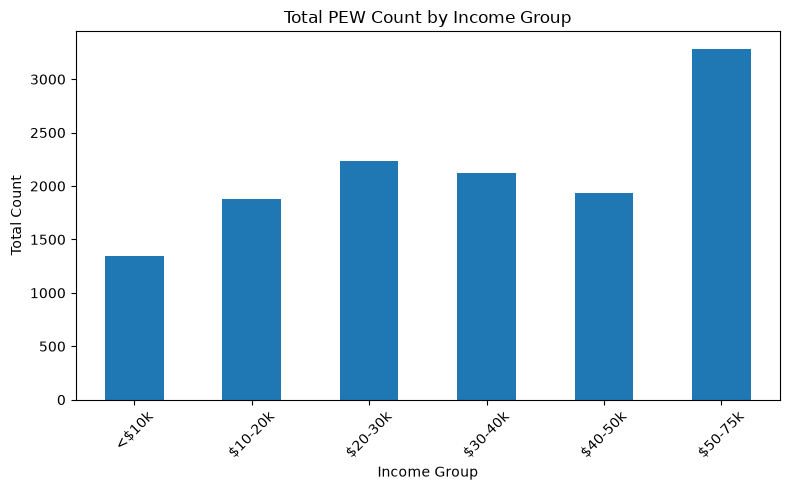

In [5]:
income_totals = (
    df_pew_tidy
    .groupby("income", sort=False)["count"]
    .sum()
)

plt.figure(figsize=(8, 5))

income_totals.plot(kind="bar")

plt.title("Total PEW Count by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Total Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualization Observation

The bar chart compares the total counts across the different income groups in the PEW dataset. The height of each bar represents the combined count for all religions within that income category. This makes it easier to compare the income groups after the data was reshaped into tidy format.

### **Task 1.5 – PEW Reflection**

Answer **all** questions briefly in your own words:

1. What was the main structural problem with the original dataset?
2. What does `id_vars` mean in `melt()`?
3. What information moved from columns into rows?
4. How did the number of rows change after reshaping, and why?
5. Why is the long format easier to analyze or visualize?
6. What did your visualization reveal?

### PEW Observations and Reflection

1. **What was the main structural problem with the original dataset?**  
   The original dataset was in wide format. The different income ranges were stored as separate columns instead of being values in one income column.

2. **What does `id_vars` mean in `melt()`?**  
   `id_vars` tells Pandas which column should stay unchanged while the other columns are reshaped. In this dataset, `religion` was used as the identifier.

3. **What information moved from columns into rows?**  
   The income ranges such as `<$10k`, `$10-20k`, and `$20-30k` moved from column headings into values in the new `income` column. Their numeric values were stored in the `count` column.

4. **How did the number of rows change after reshaping, and why?**  
   The dataset changed from 10 rows to 60 rows. This happened because each of the 10 religions had 6 income categories, so each original row became 6 separate rows.

5. **Why is the long format easier to analyze or visualize?**  
   The long format is easier to work with because income is stored as one variable. This makes it easier to group, filter, summarize, and create charts using Pandas.

6. **What did your visualization reveal?**  
   The visualization showed that the total counts were different across income groups. The `$50-75k` income group had the highest total count, while the `<$10k` group had the lowest total count.

# **Section 2 – Billboard Dataset**

## **Learning Topic: Advanced Data Tidying**

The Billboard dataset stores weekly song rankings across many week columns. You will reshape those columns into rows, clean the resulting week labels, convert ranking values to appropriate data types, handle missing values, and analyze ranking trends.

### Required concepts
- `pd.melt()` or `DataFrame.melt()`
- Pandas string methods such as:
  - `.str.replace()`
  - `.str.strip()`
  - `.str.extract()`
  - `.str.upper()`
  - `.str.lower()`
- numeric conversion
- missing-value handling
- dates / timedeltas where appropriate

## **Getting the Billboard Dataset from the Internet**

Use the **Billboard weekly ranking dataset** associated with the classic tidy-data example. The correct file contains song information plus many weekly ranking columns such as `1st week`, `2nd week`, etc. (column names can vary slightly between copies).

### Recommended method — download in your browser

1. Open this public copy of `billboard.csv`:
   `https://gist.githubusercontent.com/AdrianLl/bd94c12f2b3c3a899c4ca13d0a548966/raw/billboard.csv`
2. Save the file as **`billboard.csv`**.
3. Place it inside your project's **`data`** folder.
4. Your project should now include:

```text
project/
├── week5Lab.ipynb
└── data/
    ├── pew-raw.csv
    └── billboard.csv
```

5. Load the local file. If ordinary UTF-8 decoding fails, try `encoding="unicode_escape"`:

```python
billboard = pd.read_csv("./data/billboard.csv", encoding="unicode_escape")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://gist.githubusercontent.com/AdrianLl/bd94c12f2b3c3a899c4ca13d0a548966/raw/billboard.csv"
billboard = pd.read_csv(url, encoding="unicode_escape")
billboard.to_csv("./data/billboard.csv", index=False)
```

### Verify before continuing

Inspect `billboard.columns`. You should see identifying information for songs/artists and a sequence of weekly ranking columns. Those repeated week columns are the columns you will later reshape with `melt()`.

> **Important:** Different online copies sometimes use slightly different column names. Do not blindly copy column names from an example. Inspect **your downloaded file** first and adapt your code accordingly.

### **Task 2.1 – Load and Inspect Billboard Data**

1. Load the Billboard dataset.
2. If normal UTF-8 decoding fails, try `encoding="unicode_escape"`.
3. Display its shape, columns, and first rows.
4. Identify the columns that represent weekly rankings.

In [6]:
billboard = pd.read_csv(
    "./data/billboard.csv",
    encoding="unicode_escape"
)

print("Shape of Billboard dataset:")
print(billboard.shape)

print("\nColumn names:")
print(billboard.columns)

print("\nData types:")
print(billboard.dtypes)

print("\nFirst 5 rows:")
display(billboard.head())

Shape of Billboard dataset:
(159, 77)

Column names:
Index(['artist', 'track', 'duration', 'genre', 'date entered', 'date peaked',
       'weeks to peak', 'weeks on chart', 'worst position', 'best position',
       'enter rank', 'exit rank', '1st week', '2nd week', '3rd week',
       '4th week', '5th week', '6th week', '7th week', '8th week', '9th week',
       '10th week', '11th week', '12th week', '13th week', '14th week',
       '15th week', '16th week', '17th week', '18th week', '19th week',
       '20th week', '21st week', '22nd week', '23rd week', '24th week',
       '25th week', '26th week', '27th week', '28th week', '29th week',
       '30th week', '31st week', '32nd week', '33rd week', '34th week',
       '35th week', '36th week', '37th week', '38th week', '39th week',
       '40th week', '41st week', '42nd week', '43rd week', '44th week',
       '45th week', '46th week', '47th week', '48th week', '49th week',
       '50th week', '51st week', '52nd week', '53rd week', '54th we

,artist,track,duration,genre,date entered,date peaked,weeks to peak,weeks on chart,worst position,best position,enter rank,exit rank,1st week,2nd week,3rd week,4th week,5th week,6th week,7th week,8th week,9th week,10th week,11th week,12th week,13th week,14th week,15th week,16th week,17th week,18th week,19th week,20th week,21st week,22nd week,23rd week,24th week,25th week,26th week,27th week,28th week,29th week,30th week,31st week,32nd week,33rd week,34th week,35th week,36th week,37th week,38th week,39th week,40th week,41st week,42nd week,43rd week,44th week,45th week,46th week,47th week,48th week,49th week,50th week,51st week,52nd week,53rd week,54th week,55th week,56th week,57th week,58th week,59th week,60th week,61st week,62nd week,63rd week,64th week,65th week
0,Destiny's Child,Independent Women Part I,218,Rock,9/23/2000,11/18/2000,8,28,78,1,78,31,78,63.0,49.0,33.0,23.0,15.0,7.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0,7.0,10.0,12.0,15.0,22.0,29.0,31.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Santana,"Maria, Maria",258,Rock,2/12/2000,4/8/2000,8,26,48,1,15,47,15,8.0,6.0,5.0,2.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,8.0,15.0,19.0,21.0,26.0,36.0,48.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Savage Garden,I Knew I Loved You,247,Rock,10/23/1999,1/29/2000,14,33,71,1,71,47,71,48.0,43.0,31.0,20.0,13.0,7.0,6.0,4.0,4.0,4.0,6.0,4.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,4.0,8.0,8.0,12.0,14.0,17.0,21.0,24.0,30.0,34.0,37.0,46.0,47.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Madonna,Music,225,Rock,8/12/2000,9/16/2000,5,24,44,1,41,44,41,23.0,18.0,14.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,4.0,8.0,11.0,16.0,20.0,25.0,27.0,27.0,29.0,44.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"Aguilera, Christina",Come On Over Baby (All I Want Is You),218,Rock,8/5/2000,10/14/2000,10,21,57,1,57,44,57,47.0,45.0,29.0,23.0,18.0,11.0,9.0,9.0,11.0,1.0,1.0,1.0,1.0,4.0,8.0,12.0,22.0,23.0,43.0,44.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Task 2.2 – Diagnose the Tidiness Problem**

Explain why having columns such as week 1, week 2, week 3, etc. makes the dataset difficult to analyze.

Identify:

- identifier columns;
- weekly measured columns; and
- the variables you want after reshaping.

### Billboard Tidiness Problem

The Billboard dataset is not fully tidy because the weekly rankings are stored in separate columns such as `1st week`, `2nd week`, and `3rd week`. The week number should be one variable instead of being spread across many column names.

The identifier columns include `artist`, `track`, `duration`, `genre`, `date entered`, `date peaked`, `weeks to peak`, `weeks on chart`, `worst position`, `best position`, `enter rank`, and `exit rank`.

The weekly measured columns are `1st week` through `65th week`.

After reshaping, I want to keep the song information and create two new variables: `Week` for the week number and `Rank` for the Billboard ranking in that week.

### **Task 2.3 – Reshape with `melt()`**

Reshape the weekly ranking columns into a long structure.

Your result should contain:

- the song/artist identifiers;
- a `Week`-type column; and
- a `Rank`-type column.

In [7]:
# Identify the weekly ranking columns
week_columns = [
    col for col in billboard.columns
    if col.endswith("week")
]

# Everything else will stay as identifier information
id_columns = [
    col for col in billboard.columns
    if col not in week_columns
]

# Reshape from wide format to long format
billboard_tidy = billboard.melt(
    id_vars=id_columns,
    value_vars=week_columns,
    var_name="Week",
    value_name="Rank"
)

print("Original shape:", billboard.shape)
print("Reshaped shape:", billboard_tidy.shape)

display(billboard_tidy.head(10))

Original shape: (159, 77)
Reshaped shape: (10335, 14)


,artist,track,duration,genre,date entered,date peaked,weeks to peak,weeks on chart,worst position,best position,enter rank,exit rank,Week,Rank
0,Destiny's Child,Independent Women Part I,218,Rock,9/23/2000,11/18/2000,8,28,78,1,78,31,1st week,78.0
1,Santana,"Maria, Maria",258,Rock,2/12/2000,4/8/2000,8,26,48,1,15,47,1st week,15.0
2,Savage Garden,I Knew I Loved You,247,Rock,10/23/1999,1/29/2000,14,33,71,1,71,47,1st week,71.0
3,Madonna,Music,225,Rock,8/12/2000,9/16/2000,5,24,44,1,41,44,1st week,41.0
4,"Aguilera, Christina",Come On Over Baby (All I Want Is You),218,Rock,8/5/2000,10/14/2000,10,21,57,1,57,44,1st week,57.0
5,Janet,Doesn't Really Matter,257,Rock,6/17/2000,8/26/2000,10,24,59,1,59,41,1st week,59.0
6,Destiny's Child,Say My Name,271,Rock'n'roll,12/25/1999,3/18/2000,12,32,83,1,83,47,1st week,83.0
7,"Iglesias, Enrique",Be With You,216,Latin,4/1/2000,6/24/2000,12,20,63,1,63,28,1st week,63.0
8,Sisqo,Incomplete,232,Rock'n'roll,6/24/2000,8/12/2000,7,26,77,1,77,46,1st week,77.0
9,Lonestar,Amazed,265,Country,6/5/1999,3/4/2000,39,55,81,1,81,50,1st week,81.0


### **Task 2.4 – Clean the Week Labels with String Operations**

Use Pandas string manipulation to clean the week labels.

Demonstrate **at least three** relevant string operations. Examples include:

```python
.str.replace(...)
.str.strip()
.str.extract(...)
.str.lower()
.str.upper()
```

Convert the extracted week number to a numeric type after cleaning.

In [8]:
# Clean the week labels using string operations
billboard_tidy["Week_clean"] = (
    billboard_tidy["Week"]
    .str.strip()                          # remove extra spaces
    .str.lower()                          # convert text to lowercase
    .str.replace("week", "", regex=False) # remove the word "week"
)

# Extract only the number from labels such as "1st", "2nd", "3rd"
billboard_tidy["Week_number"] = (
    billboard_tidy["Week_clean"]
    .str.extract(r"(\d+)")[0]
)

# Convert the extracted week number from text to numeric
billboard_tidy["Week_number"] = pd.to_numeric(
    billboard_tidy["Week_number"]
)

display(
    billboard_tidy[
        ["Week", "Week_clean", "Week_number", "Rank"]
    ].head(10)
)

,Week,Week_clean,Week_number,Rank
0,1st week,1st,1,78.0
1,1st week,1st,1,15.0
2,1st week,1st,1,71.0
3,1st week,1st,1,41.0
4,1st week,1st,1,57.0
5,1st week,1st,1,59.0
6,1st week,1st,1,83.0
7,1st week,1st,1,63.0
8,1st week,1st,1,77.0
9,1st week,1st,1,81.0


### **Task 2.5 – Clean Ranking Values and Missing Data**

1. Convert ranking values to numeric using an appropriate method such as `pd.to_numeric()`.
2. Identify missing rankings.
3. Decide whether missing ranking rows should be dropped, retained, or treated another way.
4. Explain your decision.

In [9]:
# Convert Rank values to numeric
billboard_tidy["Rank"] = pd.to_numeric(
    billboard_tidy["Rank"],
    errors="coerce"
)

# Count missing ranking values
missing_ranks = billboard_tidy["Rank"].isna().sum()

print("Missing Rank values:")
print(missing_ranks)

# Remove rows where no Billboard ranking was recorded
billboard_clean = billboard_tidy.dropna(
    subset=["Rank"]
).copy()

print("\nRows before removing missing ranks:")
print(billboard_tidy.shape)

print("\nRows after removing missing ranks:")
print(billboard_clean.shape)

display(
    billboard_clean[
        ["artist", "track", "Week_number", "Rank"]
    ].head(10)
)

Missing Rank values:
6758

Rows before removing missing ranks:
(10335, 16)

Rows after removing missing ranks:
(3577, 16)


,artist,track,Week_number,Rank
0,Destiny's Child,Independent Women Part I,1,78.0
1,Santana,"Maria, Maria",1,15.0
2,Savage Garden,I Knew I Loved You,1,71.0
3,Madonna,Music,1,41.0
4,"Aguilera, Christina",Come On Over Baby (All I Want Is You),1,57.0
5,Janet,Doesn't Really Matter,1,59.0
6,Destiny's Child,Say My Name,1,83.0
7,"Iglesias, Enrique",Be With You,1,63.0
8,Sisqo,Incomplete,1,77.0
9,Lonestar,Amazed,1,81.0


### Missing Ranking Decision

I converted the ranking values to numeric and checked for missing values. I decided to remove rows where `Rank` was missing because a missing ranking means there is no valid Billboard ranking recorded for that song in that week. Filling these values with an average or another number could create an artificial ranking trend.

### **Task 2.6 – Optional Date Enhancement**

If the dataset contains a song's entry date, calculate the approximate chart date for each weekly observation using a `Timedelta`.

Document the equation you use and check for off-by-one-week errors.

In [10]:
# Convert the entry date to a real datetime value
billboard_clean["date entered"] = pd.to_datetime(
    billboard_clean["date entered"]
)

# Calculate the date for each weekly ranking
billboard_clean["Chart_Date"] = (
    billboard_clean["date entered"]
    + pd.to_timedelta(
        (billboard_clean["Week_number"] - 1) * 7,
        unit="D"
    )
)

display(
    billboard_clean[
        ["artist", "track", "date entered",
         "Week_number", "Chart_Date", "Rank"]
    ].head(10)
)

,artist,track,date entered,Week_number,Chart_Date,Rank
0,Destiny's Child,Independent Women Part I,2000-09-23,1,2000-09-23,78.0
1,Santana,"Maria, Maria",2000-02-12,1,2000-02-12,15.0
2,Savage Garden,I Knew I Loved You,1999-10-23,1,1999-10-23,71.0
3,Madonna,Music,2000-08-12,1,2000-08-12,41.0
4,"Aguilera, Christina",Come On Over Baby (All I Want Is You),2000-08-05,1,2000-08-05,57.0
5,Janet,Doesn't Really Matter,2000-06-17,1,2000-06-17,59.0
6,Destiny's Child,Say My Name,1999-12-25,1,1999-12-25,83.0
7,"Iglesias, Enrique",Be With You,2000-04-01,1,2000-04-01,63.0
8,Sisqo,Incomplete,2000-06-24,1,2000-06-24,77.0
9,Lonestar,Amazed,1999-06-05,1,1999-06-05,81.0


### Date Calculation

I calculated the date for each weekly ranking using the song's entry date. Since the entry date represents week 1, I used:

`Chart Date = Entry Date + (Week Number - 1) × 7 days`

Subtracting 1 prevents week 1 from being incorrectly moved forward by one week.

### **Task 2.7 – Billboard Visualization and Trend Analysis**

Create at least **one visualization** showing a meaningful Billboard trend.

Examples:

- ranking over time for a selected song;
- comparison of ranking trajectories for multiple songs;
- distribution of chart ranks by week.

Remember: on Billboard, a **smaller rank number is better**.

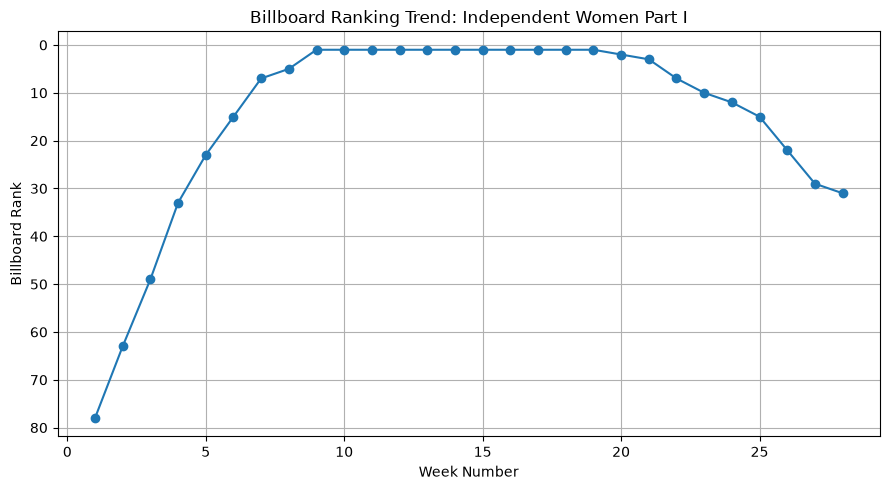

In [11]:
selected_song = billboard_clean[
    billboard_clean["track"] == "Independent Women Part I"
].copy()

plt.figure(figsize=(9, 5))

plt.plot(
    selected_song["Week_number"],
    selected_song["Rank"],
    marker="o"
)

plt.title("Billboard Ranking Trend: Independent Women Part I")
plt.xlabel("Week Number")
plt.ylabel("Billboard Rank")

# Rank 1 should appear at the top because it is the best rank
plt.gca().invert_yaxis()

plt.grid(True)
plt.tight_layout()
plt.show()

### Billboard Trend Observation

The chart shows how the ranking of *Independent Women Part I* changed over time. The song started at a lower chart position and improved over the following weeks until it reached rank 1. It remained near the top of the Billboard chart for several weeks before its ranking began to decline.

### **Task 2.8 – Billboard Reflection**

Answer all questions:

1. Why was `melt()` appropriate for the weekly ranking columns?
2. Which string operations did you use and what did each accomplish?
3. Why should the cleaned week number be numeric?
4. How did you handle missing ranking values, and why?
5. What trend did your visualization reveal?
6. What data-quality issue could lead to an incorrect ranking trend?
7. How is this Billboard transformation more complex than the PEW transformation?

### Billboard Observations and Reflection

1. **Why was `melt()` appropriate for the weekly ranking columns?**  
   `melt()` was appropriate because the weekly rankings were spread across many separate columns such as `1st week`, `2nd week`, and `3rd week`. It converted them into rows with one `Week` column and one `Rank` column.

2. **Which string operations did you use and what did each accomplish?**  
   I used `.str.strip()` to remove extra spaces, `.str.lower()` to make the text lowercase, `.str.replace()` to remove the word `week`, and `.str.extract()` to extract the numeric week value.

3. **Why should the cleaned week number be numeric?**  
   The week number should be numeric so that it can be sorted correctly, used in calculations, and plotted in the correct order.

4. **How did you handle missing ranking values, and why?**  
   I removed rows where the `Rank` value was missing. A missing rank means that there was no valid ranking recorded for that song during that week, so filling it with an artificial value could create a misleading trend.

5. **What trend did your visualization reveal?**  
   The visualization showed that *Independent Women Part I* improved in ranking over time, reached rank 1, stayed near the top of the chart for several weeks, and then began to decline.

6. **What data-quality issue could lead to an incorrect ranking trend?**  
   Missing ranking values, incorrect week labels, or ranking values stored as text could produce an incorrect trend if they were not cleaned properly.

7. **How is this Billboard transformation more complex than the PEW transformation?**  
   The Billboard transformation was more complex because it required reshaping many weekly columns, cleaning week labels with string operations, converting values to numeric types, handling missing rankings, and calculating dates. The PEW transformation mainly required reshaping the income columns.

# **Section 3 – Data Cleaning (Cars Dataset)**

## **Learning Topic: Data Cleaning and Missing Data Handling**

Data cleaning includes identifying invalid, irrelevant, duplicated, inconsistent, or missing data and deciding how to treat it.

In this section you will work with the Auto MPG / Cars dataset and compare several missing-data strategies.

### Required functions and concepts

- `isnull()` / `isna()`
- `notnull()` / `notna()`
- `dropna()`
- `fillna()`
- `mean()`
- `median()`
- `mode()`
- duplicate detection/removal
- numeric conversion
- `SimpleImputer`

## **Getting the Cars (Auto MPG) Dataset from the Internet**

Use the **Auto MPG** dataset from the UCI Machine Learning Repository. UCI describes it as a regression dataset concerning city-cycle fuel consumption. It contains variables such as MPG, cylinders, displacement, horsepower, weight, acceleration, model year, origin, and car name.

### Recommended source

Official UCI dataset page:

`https://archive.ics.uci.edu/dataset/9/auto+mpg`

The UCI page provides the dataset files and documentation. The raw file is named **`auto-mpg.data`** rather than `cars.csv`.

### Recommended student workflow

1. Open the UCI page above.
2. Download the Auto MPG dataset.
3. Extract the downloaded archive if necessary.
4. Locate **`auto-mpg.data`**.
5. Place it in your project's `data/` folder.
6. Keep the original raw file rather than editing it manually.

Your project can look like:

```text
project/
├── week5Lab.ipynb
└── data/
    └── auto-mpg.data
```

### Loading the UCI raw file with Pandas

Because this file is whitespace-delimited rather than a normal comma-separated CSV, supply the column names when reading it:

```python
column_names = [
    "MPG", "Cylinders", "Displacement", "Horsepower",
    "Weight", "Acceleration", "ModelYear", "Origin", "CarName"
]

cars = pd.read_csv(
    "./data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)
```

The `na_values="?"` argument is important because the UCI dataset uses `?` for missing horsepower values.

### Optional: create a local CSV working copy

After correctly loading the original UCI file, you may save a CSV copy:

```python
cars.to_csv("./data/cars.csv", index=False)
```

You can then reload it later with:

```python
cars = pd.read_csv("./data/cars.csv")
```

### Verify before continuing

Check:

```python
cars.shape
cars.head()
cars.dtypes
cars.isnull().sum()
```

The UCI version contains **398 instances**, and `Horsepower` contains missing values. If your results are substantially different, verify your download and loading code.

> **Good practice:** Preserve the original raw file. If you create `cars.csv`, treat it as a derived working copy rather than silently replacing the source data.

### **Task 3.1 – Load and Inspect the Cars Dataset**

1. Load the Cars dataset from your data folder.
2. Inspect shape, columns, data types, and sample rows.
3. Determine whether any row contains metadata or data-type labels rather than an actual car observation.
4. Remove irrelevant rows **only if justified by inspection**.

In [12]:
column_names = [
    "MPG",
    "Cylinders",
    "Displacement",
    "Horsepower",
    "Weight",
    "Acceleration",
    "ModelYear",
    "Origin",
    "CarName"
]

cars = pd.read_csv(
    "./data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)

print("Shape:")
print(cars.shape)

print("\nColumn names:")
print(cars.columns)

print("\nData types:")
print(cars.dtypes)

print("\nFirst 5 rows:")
display(cars.head())

print("\nLast 5 rows:")
display(cars.tail())

Shape:
(398, 9)

Column names:
Index(['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight',
       'Acceleration', 'ModelYear', 'Origin', 'CarName'],
      dtype='str')

Data types:
MPG             float64
Cylinders         int64
Displacement    float64
Horsepower      float64
Weight          float64
Acceleration    float64
ModelYear         int64
Origin            int64
CarName             str
dtype: object

First 5 rows:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,ModelYear,Origin,CarName
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



Last 5 rows:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,ModelYear,Origin,CarName
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10


### **Task 3.2 – Assess Missing and Invalid Values**

1. Count missing values in every column.
2. Calculate the percentage of missing values.
3. Use `notnull()` or `notna()` at least once to confirm valid observations.
4. Check for values that should be numeric but are stored as text.
5. Convert columns to appropriate data types where needed.

In [13]:
# Count missing values in each column
missing_count = cars.isna().sum()

print("Missing values:")
print(missing_count)


# Calculate the percentage of missing values
missing_percentage = (cars.isna().sum() / len(cars)) * 100

print("\nMissing value percentages:")
print(missing_percentage)


# Count valid (non-missing) observations
print("\nValid values in each column:")
print(cars.notna().sum())


# Check current data types
print("\nData types before conversion:")
print(cars.dtypes)

Missing values:
MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
ModelYear       0
Origin          0
CarName         0
dtype: int64

Missing value percentages:
MPG             0.000000
Cylinders       0.000000
Displacement    0.000000
Horsepower      1.507538
Weight          0.000000
Acceleration    0.000000
ModelYear       0.000000
Origin          0.000000
CarName         0.000000
dtype: float64

Valid values in each column:
MPG             398
Cylinders       398
Displacement    398
Horsepower      392
Weight          398
Acceleration    398
ModelYear       398
Origin          398
CarName         398
dtype: int64

Data types before conversion:
MPG             float64
Cylinders         int64
Displacement    float64
Horsepower      float64
Weight          float64
Acceleration    float64
ModelYear         int64
Origin            int64
CarName             str
dtype: object


In [14]:
numeric_columns = [
    "MPG",
    "Cylinders",
    "Displacement",
    "Horsepower",
    "Weight",
    "Acceleration",
    "ModelYear",
    "Origin"
]

for col in numeric_columns:
    cars[col] = pd.to_numeric(
        cars[col],
        errors="coerce"
    )

print("\nData types after numeric conversion:")
print(cars.dtypes)


Data types after numeric conversion:
MPG             float64
Cylinders         int64
Displacement    float64
Horsepower      float64
Weight          float64
Acceleration    float64
ModelYear         int64
Origin            int64
CarName             str
dtype: object


### **Task 3.3 – Check Duplicates**

Identify duplicate records.

- Report the number of duplicates.
- Remove duplicates if present.
- If there are none, state that clearly.

In [15]:
# Check for duplicate rows
duplicate_count = cars.duplicated().sum()

print("Number of duplicate rows:")
print(duplicate_count)

# Show duplicate rows, if any
duplicates = cars[cars.duplicated()]

display(duplicates)

Number of duplicate rows:
0


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,ModelYear,Origin,CarName


### Duplicate Check

I checked the Cars dataset for duplicate rows using `duplicated()`. If duplicate records were present, they would be removed using `drop_duplicates()`. If no duplicates were found, no rows were removed.

### **Task 3.4 – Compare Missing-Value Strategies**

Create copies of the data so you can compare approaches.

Demonstrate:

1. dropping rows with missing values using `dropna()`;
2. dropping columns with missing values and explaining why this may be too aggressive;
3. filling a numeric variable with its **mean**;
4. filling a numeric variable with its **median**;
5. using **mode** where appropriate for a categorical/discrete variable.

Do not automatically assume one strategy is best.

In [16]:
# Make a copy so the original Cars dataframe stays unchanged
cars_drop_rows = cars.copy()

# Remove rows that contain at least one missing value
cars_drop_rows = cars_drop_rows.dropna()

print("Original shape:")
print(cars.shape)

print("\nShape after dropping rows with missing values:")
print(cars_drop_rows.shape)

Original shape:
(398, 9)

Shape after dropping rows with missing values:
(392, 9)


In [17]:
# Make another copy
cars_drop_columns = cars.copy()

# Remove any column that contains missing values
cars_drop_columns = cars_drop_columns.dropna(axis=1)

print("Original shape:")
print(cars.shape)

print("\nShape after dropping columns with missing values:")
print(cars_drop_columns.shape)

print("\nRemaining columns:")
print(cars_drop_columns.columns)

Original shape:
(398, 9)

Shape after dropping columns with missing values:
(398, 8)

Remaining columns:
Index(['MPG', 'Cylinders', 'Displacement', 'Weight', 'Acceleration',
       'ModelYear', 'Origin', 'CarName'],
      dtype='str')


### Comparing Dropping Strategies

Using `dropna()` on rows removes the observations that contain missing values. In this dataset, this removes only a small number of cars.

Using `dropna(axis=1)` removes the entire `Horsepower` column because it contains missing values. This is more aggressive because most horsepower values are valid, so removing the whole feature would discard useful information.

In [18]:
# Mean imputation
cars_mean = cars.copy()

horsepower_mean = cars_mean["Horsepower"].mean()

cars_mean["Horsepower"] = cars_mean["Horsepower"].fillna(
    horsepower_mean
)

print("Horsepower mean:")
print(horsepower_mean)

print("\nMissing Horsepower values after mean imputation:")
print(cars_mean["Horsepower"].isna().sum())

Horsepower mean:
104.46938775510205

Missing Horsepower values after mean imputation:
0


In [19]:
# Median imputation
cars_median = cars.copy()

horsepower_median = cars_median["Horsepower"].median()

cars_median["Horsepower"] = cars_median["Horsepower"].fillna(
    horsepower_median
)

print("Horsepower median:")
print(horsepower_median)

print("\nMissing Horsepower values after median imputation:")
print(cars_median["Horsepower"].isna().sum())

Horsepower median:
93.5

Missing Horsepower values after median imputation:
0


In [20]:
# Mode imputation for a discrete variable
cars_mode = cars.copy()

origin_mode = cars_mode["Origin"].mode()[0]

cars_mode["Origin"] = cars_mode["Origin"].fillna(
    origin_mode
)

print("Most common Origin value:")
print(origin_mode)

print("\nMissing Origin values after mode imputation:")
print(cars_mode["Origin"].isna().sum())

Most common Origin value:
1

Missing Origin values after mode imputation:
0


### Imputation Comparison

For `Horsepower`, I compared mean and median imputation. Mean imputation replaces missing values with the average Horsepower, while median imputation uses the middle Horsepower value.

For the discrete `Origin` variable, mode is more appropriate because it represents the most frequently occurring category. The original `Origin` column did not contain missing values, so no values actually needed to be replaced.

The best imputation method depends on the type and distribution of the variable, so one method should not automatically be used for every column.

### **Task 3.5 – Use Visualization to Support an Imputation Decision**

Choose a numeric feature such as `MPG`.

1. Plot its distribution.
2. Describe whether it appears symmetric or skewed.
3. Use that evidence to justify whether **mean or median** is a better simple imputation choice.

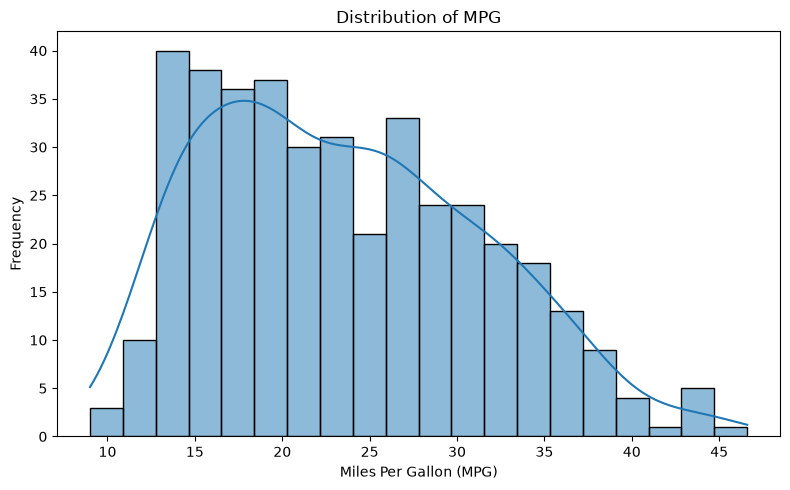

MPG mean: 23.514572864321607
MPG median: 23.0


In [21]:
# Plot the distribution of MPG
plt.figure(figsize=(8, 5))

sns.histplot(
    cars["MPG"],
    bins=20,
    kde=True
)

plt.title("Distribution of MPG")
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# Calculate mean and median
mpg_mean = cars["MPG"].mean()
mpg_median = cars["MPG"].median()

print("MPG mean:", mpg_mean)
print("MPG median:", mpg_median)

### MPG Distribution and Imputation Decision

The MPG distribution is slightly right-skewed because the values extend farther toward the higher MPG range. The mean MPG is approximately 23.51 and the median is 23.0, so the two values are quite close.

For a simple imputation method, I would choose the median because it is less affected by unusually high or low values. However, since the mean and median are very similar, either method would give a reasonably similar result for this dataset.

### **Task 3.6 – Apply `SimpleImputer`**

Use Scikit-Learn's `SimpleImputer` on at least one appropriate feature.

Remember the two main stages:

1. `fit` – learn the replacement statistic from the data;
2. `transform` – replace missing values using that statistic.

You may use `fit_transform()` when appropriate, but explain what it combines.

In [22]:
from sklearn.impute import SimpleImputer

# Make a copy so the original dataframe stays unchanged
cars_imputed = cars.copy()

# Create an imputer that will use the median
imputer = SimpleImputer(strategy="median")

# Learn the median Horsepower value
imputer.fit(cars_imputed[["Horsepower"]])

print("Median learned by SimpleImputer:")
print(imputer.statistics_[0])

# Replace missing Horsepower values
cars_imputed[["Horsepower"]] = imputer.transform(
    cars_imputed[["Horsepower"]]
)

print("\nMissing Horsepower values after SimpleImputer:")
print(cars_imputed["Horsepower"].isna().sum())

Median learned by SimpleImputer:
93.5

Missing Horsepower values after SimpleImputer:
0


### SimpleImputer

I used Scikit-Learn's `SimpleImputer` with the median strategy for the `Horsepower` column. The `fit()` step learned the median Horsepower value from the available data, and the `transform()` step replaced the missing values using that learned median.

`fit_transform()` could also perform both steps at once, but I used them separately here to clearly show the difference between learning the replacement value and applying it.

### **Task 3.7 – Validate the Cleaned Cars Dataset**

Compare the dataset **before and after cleaning**.

Report:

- shape;
- missing-value counts;
- duplicate counts;
- descriptive statistics for selected numeric columns.

Create at least **one visualization** supporting your comparison.

In [23]:
print("Original shape:")
print(cars.shape)

print("\nCleaned shape:")
print(cars_imputed.shape)

print("\nMissing values before cleaning:")
print(cars.isna().sum())

print("\nMissing values after cleaning:")
print(cars_imputed.isna().sum())

print("\nDuplicate rows before cleaning:")
print(cars.duplicated().sum())

print("\nDuplicate rows after cleaning:")
print(cars_imputed.duplicated().sum())

print("\nOriginal descriptive statistics:")
display(
    cars[["MPG", "Horsepower", "Weight"]].describe()
)

print("\nCleaned descriptive statistics:")
display(
    cars_imputed[["MPG", "Horsepower", "Weight"]].describe()
)

Original shape:
(398, 9)

Cleaned shape:
(398, 9)

Missing values before cleaning:
MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
ModelYear       0
Origin          0
CarName         0
dtype: int64

Missing values after cleaning:
MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
ModelYear       0
Origin          0
CarName         0
dtype: int64

Duplicate rows before cleaning:
0

Duplicate rows after cleaning:
0

Original descriptive statistics:


,MPG,Horsepower,Weight
count,398.000000,392.000000,398.000000
mean,23.514573,104.469388,2970.424623
std,7.815984,38.491160,846.841774
min,9.000000,46.000000,1613.000000
25%,17.500000,75.000000,2223.750000
50%,23.000000,93.500000,2803.500000
75%,29.000000,126.000000,3608.000000
max,46.600000,230.000000,5140.000000



Cleaned descriptive statistics:


,MPG,Horsepower,Weight
count,398.000000,398.000000,398.000000
mean,23.514573,104.304020,2970.424623
std,7.815984,38.222625,846.841774
min,9.000000,46.000000,1613.000000
25%,17.500000,76.000000,2223.750000
50%,23.000000,93.500000,2803.500000
75%,29.000000,125.000000,3608.000000
max,46.600000,230.000000,5140.000000


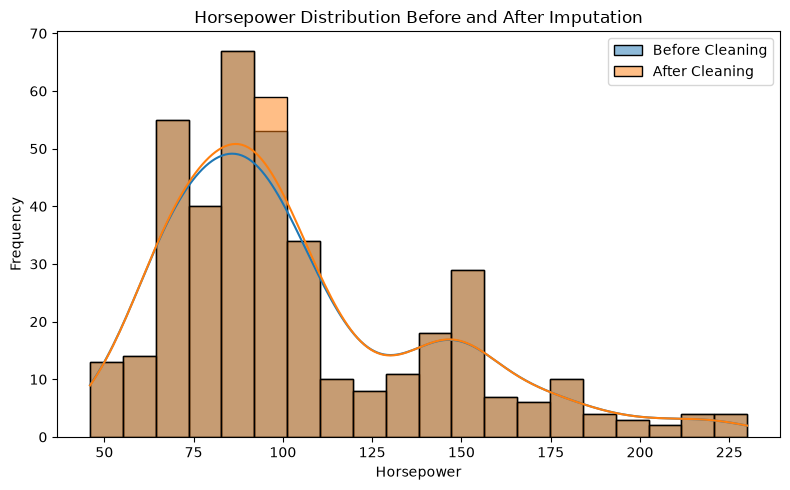

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    cars["Horsepower"],
    bins=20,
    kde=True,
    label="Before Cleaning"
)

sns.histplot(
    cars_imputed["Horsepower"],
    bins=20,
    kde=True,
    label="After Cleaning",
    alpha=0.5
)

plt.title("Horsepower Distribution Before and After Imputation")
plt.xlabel("Horsepower")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

### Cars Dataset Validation

After cleaning, the dataset kept the same number of rows and columns because missing `Horsepower` values were imputed rather than removed. The missing-value count for `Horsepower` decreased from 6 to 0, while the duplicate count remained unchanged.

The descriptive statistics before and after cleaning were very similar, which suggests that median imputation did not greatly change the overall distribution of the data. The visualization also shows that the Horsepower distribution remained mostly consistent after imputation.

### **Task 3.8 – Cars Reflection**

Answer all questions:

1. What were the main data-quality problems?
2. How many missing values did you find?
3. What happened when you dropped rows containing missing values?
4. Why might dropping entire columns be inappropriate?
5. When is mean imputation reasonable?
6. When might median be safer than mean?
7. Where would mode imputation be appropriate?
8. How did `SimpleImputer` differ from manually calling `fillna()`?
9. Did cleaning materially change the dataset statistics?
10. Which cleaning decisions would you carry forward into an ML pipeline, and why?

### Cars Observations and Reflection

1. **What were the main data-quality problems?**  
   The main issue was missing values in the `Horsepower` column. I also checked for duplicate rows and verified the numeric data types.

2. **How many missing values did you find?**  
   I found 6 missing values, all in the `Horsepower` column.

3. **What happened when you dropped rows containing missing values?**  
   Dropping rows with missing values reduced the dataset from 398 rows to 392 rows. This removed the six cars with missing Horsepower values.

4. **Why might dropping entire columns be inappropriate?**  
   Dropping the entire `Horsepower` column would remove a useful feature even though only a small number of values were missing. Most of the Horsepower data was still valid.

5. **When is mean imputation reasonable?**  
   Mean imputation can be reasonable when a numeric variable is fairly symmetric and does not contain strong outliers.

6. **When might median be safer than mean?**  
   Median imputation is often safer when the data is skewed or contains unusually high or low values because the median is less affected by extreme values.

7. **Where would mode imputation be appropriate?**  
   Mode imputation is appropriate for categorical or discrete variables, such as `Origin`, because it replaces missing values with the most common category.

8. **How did `SimpleImputer` differ from manually calling `fillna()`?**  
   `fillna()` directly replaces missing values using a value that I calculate manually. `SimpleImputer` can learn the replacement value using `fit()` and then apply it using `transform()`, which makes it easier to use as part of a machine-learning pipeline.

9. **Did cleaning materially change the dataset statistics?**  
   No. The descriptive statistics before and after median imputation were very similar because only 6 Horsepower values were missing. The overall distribution remained mostly unchanged.

10. **Which cleaning decisions would you carry forward into an ML pipeline, and why?**  
    I would keep the numeric type conversions, duplicate checks, missing-value checks, and median imputation for Horsepower. I would use `SimpleImputer` in an ML pipeline because it can learn the imputation value from the training data and consistently apply the same method to new data.

# **Section 4 – Outlier Detection (Diabetes Dataset)**

## **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can result from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers matter because they can affect:

- means and standard deviations;
- correlations;
- regression coefficients;
- distance-based algorithms;
- scaling and normalization;
- model evaluation.

**Important:** Detecting an outlier does **not** automatically mean it should be deleted. You must justify treatment in the context of the data.

## **Getting the Diabetes Dataset from the Internet**

For this section, use the **Pima Indians Diabetes** CSV commonly used in introductory machine-learning exercises. The expected version has **768 observations** and these nine columns:

`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, and `Outcome`.

### Recommended method — download in your browser

A public CSV copy is available here:

`https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv`

1. Open the address above in a browser.
2. Save the file as **`diabetes.csv`**.
3. Place it in your project's **`data`** folder.
4. Load the local copy:

```python
diabetes = pd.read_csv("./data/diabetes.csv")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
diabetes = pd.read_csv(url)
diabetes.to_csv("./data/diabetes.csv", index=False)
```

### Verify before continuing

Run:

```python
diabetes.shape
diabetes.head()
diabetes.columns
```

For the expected file, the shape should be `(768, 9)` and the columns should match the list above.

### Important data-quality warning

In this dataset, some physiological variables contain **zero values** that may represent unavailable or invalid measurements rather than plausible measurements. Do not automatically treat every zero as an outlier or delete it. Inspect the variable meaning first, document your decision, and keep the focus of this section on comparing the required outlier-detection methods.

> **Dataset-name warning:** UCI also hosts a dataset simply called **Diabetes**, but it is a different time-series dataset. For this particular lab, use the nine-column Pima-style CSV described above so your work matches the assignment.

### **Task 4.1 – Load and Explore the Diabetes Dataset**

1. Load the Diabetes dataset from your data folder.
2. Display shape, columns, data types, and descriptive statistics.
3. Identify the numeric features you will examine for outliers.
4. Check for missing or obviously invalid values before outlier analysis.

In [25]:
diabetes = pd.read_csv("./data/diabetes.csv")

print("Shape:")
print(diabetes.shape)

print("\nColumns:")
print(diabetes.columns)

print("\nData types:")
print(diabetes.dtypes)

print("\nFirst 5 rows:")
display(diabetes.head())

print("\nDescriptive statistics:")
display(diabetes.describe())

Shape:
(768, 9)

Columns:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Descriptive statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [26]:
print("Missing values:")
print(diabetes.isna().sum())

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [27]:
zero_check_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zero values in selected columns:")

for col in zero_check_columns:
    print(col, ":", (diabetes[col] == 0).sum())

Zero values in selected columns:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [28]:
numeric_features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

print("Numeric features for outlier analysis:")
print(numeric_features)

Numeric features for outlier analysis:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


### **Task 4.2 – Box Plot Method**

Create box plots for selected numeric features.

Use the plots to:

- identify observations outside the whiskers;
- compare which variables appear to contain more extreme values;
- explain what the box, median, quartiles, and whiskers represent.

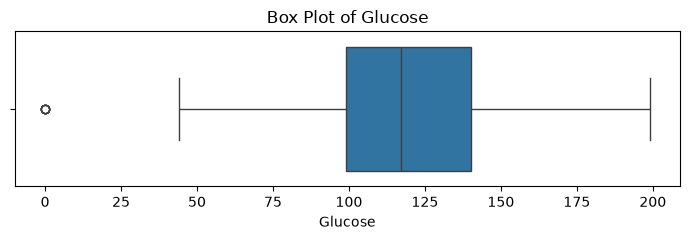

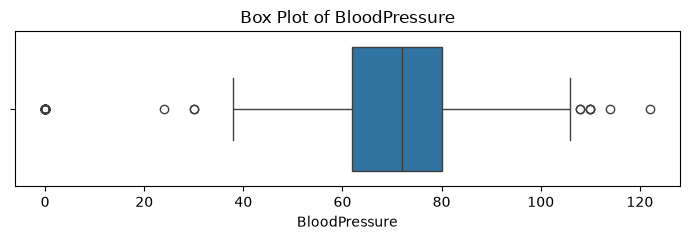

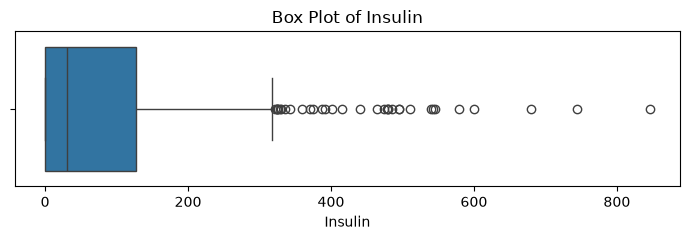

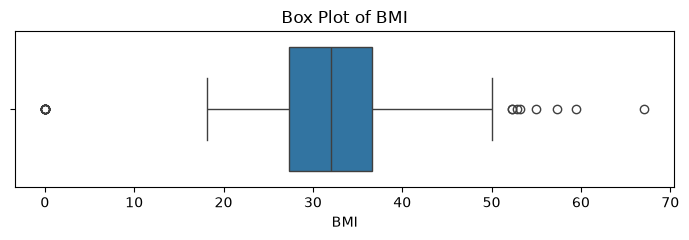

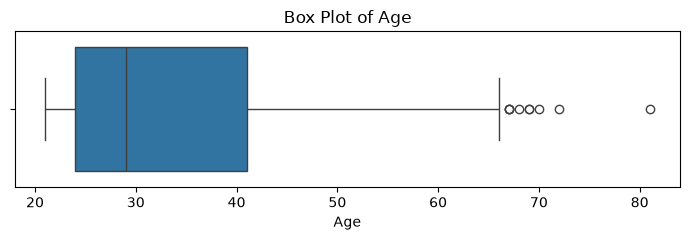

In [29]:
selected_features = [
    "Glucose",
    "BloodPressure",
    "Insulin",
    "BMI",
    "Age"
]

for col in selected_features:
    plt.figure(figsize=(7, 2.5))

    sns.boxplot(
        x=diabetes[col]
    )

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

### Box Plot Observations

The box plots show that some variables contain observations outside the whiskers. `Insulin` has many high-value potential outliers and appears to have some of the most extreme values. `BMI` also contains several observations above the upper whisker and some zero values.

In a box plot, the box represents the middle 50% of the data between the first quartile (Q1) and third quartile (Q3). The line inside the box represents the median. The whiskers show the usual range of the data, while points outside the whiskers are considered potential outliers.

These observations should not automatically be deleted because they may represent unusual but valid cases or possible data-quality problems.

### **Task 4.3 – Scatter Plot Method**

Create at least one scatter plot using two meaningful numeric features.

Use the plot to identify observations that appear isolated from the main cluster of data.

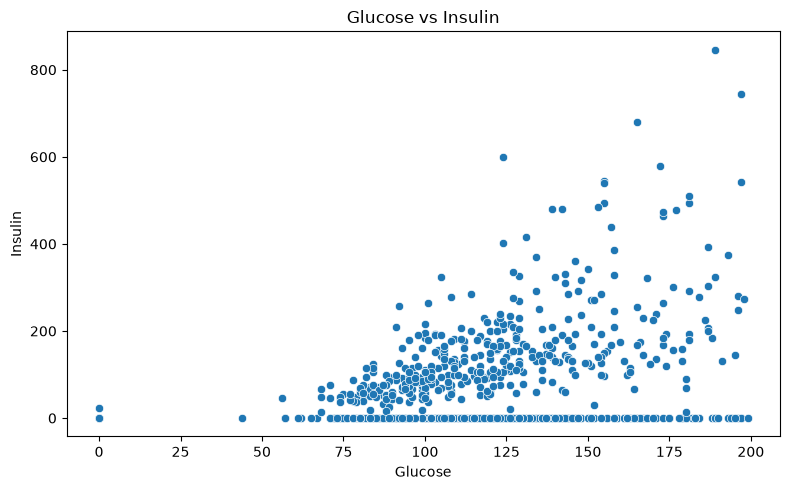

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=diabetes,
    x="Glucose",
    y="Insulin"
)

plt.title("Glucose vs Insulin")
plt.xlabel("Glucose")
plt.ylabel("Insulin")

plt.tight_layout()
plt.show()

### Scatter Plot Observation

The scatter plot shows that most observations are clustered at lower insulin values, while several observations have very high insulin values and appear isolated from the main group. These points may be potential outliers.

There are also many observations where `Insulin` is 0. These zero values may represent unavailable or invalid measurements, so they should be interpreted carefully instead of automatically being treated as normal values or deleted.

### **Task 4.4 – Z-Score Method**

For a numeric feature, calculate:

\[
z = \frac{x - \mu}{\sigma}
\]

Use the conventional threshold:

\[
|z| > 3
\]

to flag potential outliers.

Report the number of observations identified.

In [31]:
insulin_mean = diabetes["Insulin"].mean()
insulin_std = diabetes["Insulin"].std()

diabetes["Insulin_Z"] = (
    diabetes["Insulin"] - insulin_mean
) / insulin_std

z_outliers = diabetes[
    diabetes["Insulin_Z"].abs() > 3
]

print("Insulin mean:")
print(insulin_mean)

print("\nInsulin standard deviation:")
print(insulin_std)

print("\nNumber of Z-score outliers:")
print(len(z_outliers))

display(
    z_outliers[
        ["Insulin", "Insulin_Z"]
    ]
)

Insulin mean:
79.79947916666667

Insulin standard deviation:
115.24400235133817

Number of Z-score outliers:
18


,Insulin,Insulin_Z
8,543,4.019303
13,846,6.648507
111,495,3.602795
153,485,3.516023
186,495,3.602795
220,478,3.455282
228,744,5.763428
247,680,5.208085
286,545,4.036657
370,465,3.342478


### Z-Score Observation

Using the Z-score method with the threshold `|z| > 3`, I identified 18 potential outliers in the `Insulin` column. These observations are more than three standard deviations away from the mean.

The Z-score method identifies unusually distant values, but these observations should still be investigated before deciding whether they should be removed.

### **Task 4.5 – Interquartile Range (IQR) Method**

Calculate:

\[
IQR = Q3 - Q1
\]

Then calculate:

\[
Lower\ Bound = Q1 - 1.5(IQR)
\]

\[
Upper\ Bound = Q3 + 1.5(IQR)
\]

Identify observations outside those bounds and report the outlier count.

In [32]:
Q1 = diabetes["Insulin"].quantile(0.25)
Q3 = diabetes["Insulin"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = diabetes[
    (diabetes["Insulin"] < lower_bound) |
    (diabetes["Insulin"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nLower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of IQR outliers:")
print(len(iqr_outliers))

display(
    iqr_outliers[
        ["Insulin"]
    ]
)

Q1: 0.0
Q3: 127.25
IQR: 127.25

Lower bound: -190.875
Upper bound: 318.125

Number of IQR outliers:
34


,Insulin
8,543
13,846
54,342
111,495
139,325
153,485
186,495
220,478
228,744
231,370


### IQR Observation

Using the IQR method, I identified 34 potential outliers in the `Insulin` column. The upper bound was 318.125, so Insulin values above this limit were flagged.

The first quartile was 0 because many Insulin observations have a value of 0. These zero values may represent unavailable measurements, so they can affect the quartiles and the IQR calculation. Therefore, the identified outliers should be interpreted carefully.

### **Task 4.6 – Compare Detection Methods**

Create a small comparison showing the number of potential outliers identified by:

- Box Plot / IQR interpretation
- Z-Score
- IQR rule

Explain why the methods may identify different observations.

In [33]:
comparison = pd.DataFrame({
    "Method": [
        "Box Plot / IQR Interpretation",
        "Z-Score",
        "IQR Rule"
    ],
    "Potential Outliers": [
        len(iqr_outliers),
        len(z_outliers),
        len(iqr_outliers)
    ]
})

display(comparison)

,Method,Potential Outliers
0,Box Plot / IQR Interpretation,34
1,Z-Score,18
2,IQR Rule,34


### Comparison of Outlier Detection Methods

The Z-Score method identified 18 potential Insulin outliers, while the IQR method identified 34. The box plot gives the same general result as the IQR method because standard box-plot whiskers are based on the 1.5 × IQR rule.

The methods can produce different results because Z-Scores use the mean and standard deviation, while IQR uses quartiles. The Insulin distribution is skewed and contains many zero values and several very high values, so the mean and standard deviation are affected by these extreme observations. As a result, the Z-Score method flags fewer values than the IQR method.

### **Task 4.7 – Treat Outliers Carefully**

Create a cleaned copy of the dataset and remove outliers **only where you can justify doing so**.

Do not overwrite the original dataframe.

Compare before and after:

- number of rows;
- mean;
- median;
- standard deviation;
- relevant visualizations.

In [34]:
# Create a cleaned copy
diabetes_clean = diabetes.copy()

# Remove only the most extreme Insulin values using the Z-score rule
diabetes_clean = diabetes_clean[
    diabetes_clean["Insulin_Z"].abs() <= 3
].copy()

print("Rows before treatment:")
print(len(diabetes))

print("\nRows after treatment:")
print(len(diabetes_clean))


# Compare descriptive statistics
print("\nBefore treatment:")
print("Mean:", diabetes["Insulin"].mean())
print("Median:", diabetes["Insulin"].median())
print("Standard deviation:", diabetes["Insulin"].std())

print("\nAfter treatment:")
print("Mean:", diabetes_clean["Insulin"].mean())
print("Median:", diabetes_clean["Insulin"].median())
print("Standard deviation:", diabetes_clean["Insulin"].std())

Rows before treatment:
768

Rows after treatment:
750

Before treatment:
Mean: 79.79947916666667
Median: 30.5
Standard deviation: 115.24400235133817

After treatment:
Mean: 68.54266666666666
Median: 14.5
Standard deviation: 89.00995379950159


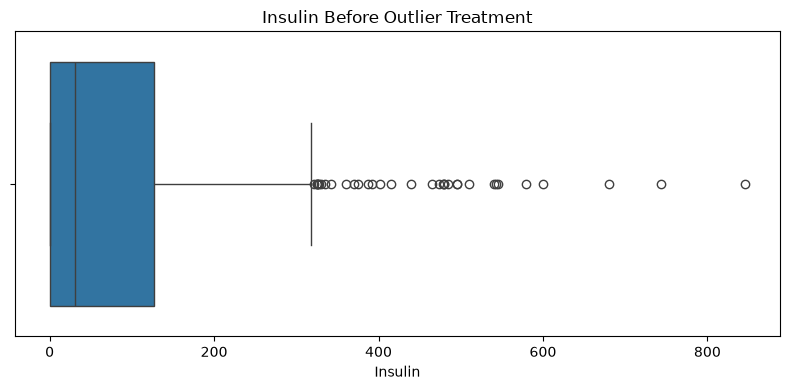

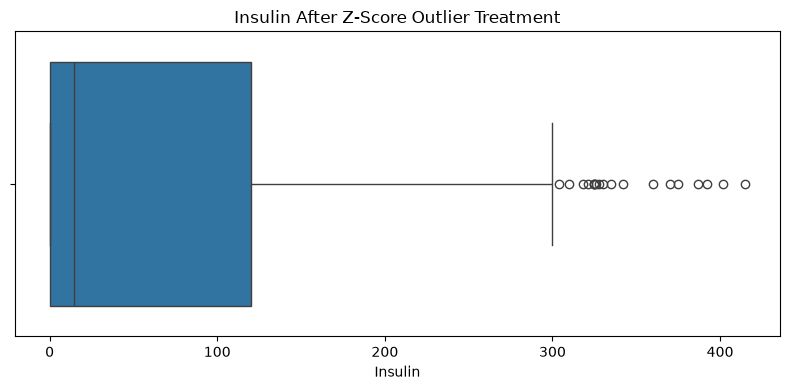

In [35]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=diabetes["Insulin"]
)

plt.title("Insulin Before Outlier Treatment")
plt.xlabel("Insulin")
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 4))

sns.boxplot(
    x=diabetes_clean["Insulin"]
)

plt.title("Insulin After Z-Score Outlier Treatment")
plt.xlabel("Insulin")
plt.tight_layout()
plt.show()

### Outlier Treatment Decision

I created a copy of the original dataset and used the Z-score method to remove only Insulin observations where `|z| > 3`. I chose this method because it was more conservative than the IQR method and only removed the most extreme values.

I did not remove Insulin values equal to 0 because these may represent unavailable measurements rather than statistical outliers, and they should be handled separately.

After removing the extreme Insulin observations, I compared the number of rows, mean, median, standard deviation, and box plots before and after treatment.

### Effect of Outlier Treatment

After applying the Z-score rule, the dataset decreased from 768 to 750 rows because 18 extreme Insulin observations were removed.

The mean Insulin value decreased from approximately 79.80 to 68.54, and the standard deviation decreased from approximately 115.24 to 89.01. This shows that the extreme high values had a noticeable effect on the average and spread of the data.

The median also decreased from 30.5 to 14.5. This dataset contains many Insulin values equal to 0, so the median is influenced by the large number of zero measurements. This is another reason the data should be interpreted carefully.

### **Task 4.8 – Diabetes Reflection**

Answer all questions:

1. What is an outlier?
2. What are at least three possible causes of outliers?
3. Which variables showed the clearest visual outliers?
4. How many observations were flagged by the Z-Score method?
5. How many were flagged by the IQR method?
6. Why can Z-Score and IQR produce different results?
7. When should an outlier be retained?
8. When might removing an outlier be justified?
9. How did removal affect the descriptive statistics?
10. How could untreated outliers affect a downstream ML model?

### Diabetes Observations and Reflection

1. **What is an outlier?**  
   An outlier is an observation that is unusually far away from most of the other values in a dataset.

2. **What are at least three possible causes of outliers?**  
   Outliers can result from measurement errors, data-entry errors, or unusual but valid observations. They can also represent rare real-world cases.

3. **Which variables showed the clearest visual outliers?**  
   `Insulin` showed the clearest extreme values in the box plot and scatter plot. `BMI` also showed several potential outliers.

4. **How many observations were flagged by the Z-Score method?**  
   The Z-Score method identified 18 potential outliers in the `Insulin` column.

5. **How many were flagged by the IQR method?**  
   The IQR method identified 34 potential outliers in the `Insulin` column.

6. **Why can Z-Score and IQR produce different results?**  
   Z-Score uses the mean and standard deviation, while IQR uses quartiles. Because the Insulin distribution is skewed and contains many zero values and some very large values, the two methods identify different numbers of outliers.

7. **When should an outlier be retained?**  
   An outlier should be retained when it represents a valid real-world observation and there is no evidence that it is caused by an error.

8. **When might removing an outlier be justified?**  
   Removing an outlier may be justified when there is evidence that it is an error or when an extremely unusual value would distort the analysis and the removal rule is clearly documented.

9. **How did removal affect the descriptive statistics?**  
   After removing the extreme Z-score outliers, the mean decreased from about 79.80 to 68.54 and the standard deviation decreased from about 115.24 to 89.01. The median also decreased from 30.5 to 14.5.

10. **How could untreated outliers affect a downstream ML model?**  
    Untreated outliers can distort averages, scaling, correlations, regression coefficients, and distance calculations. This can cause some machine-learning models to learn patterns that do not represent most of the data.

# **Final Validation and Submission Checklist**

Before submitting:

- [ ] All four required sections are in this single notebook.
- [ ] PEW uses `pd.melt()` or `DataFrame.melt()`.
- [ ] Billboard uses `melt()` and Pandas string manipulation.
- [ ] Cars demonstrates missing-value analysis, dropping, imputation, duplicates, and validation.
- [ ] Diabetes includes box plot, scatter plot, Z-Score, and IQR.
- [ ] Every required visualization has a meaningful title and axis labels.
- [ ] Reflection questions are answered in Markdown.
- [ ] Data is loaded using relative paths from a clearly named data folder.
- [ ] `README.md`, `requirements.txt`, and `.gitignore` are included.
- [ ] There are no unnecessary `!pip install` cells.
- [ ] You restarted the kernel and successfully ran **Run All** from top to bottom.

# **General Guidelines**

## Expected Observations

### PEW
- Income categories are encoded as column headings in the original wide dataset.
- `melt()` should preserve religion as an identifier while moving income categories into rows.
- The long form is easier to group, filter, and visualize.

### Billboard
- Weekly rankings are stored across repeated week columns.
- `melt()` converts weekly columns into observations.
- Week labels usually require string cleanup/extraction before numeric analysis.
- Missing rankings often indicate that a song was not ranked in that week and should not automatically be imputed.

### Cars
- Students should inspect before deleting the first row; removal should be evidence-based.
- Some numeric-looking columns may require conversion from `object`.
- Mean imputation is sensitive to skew/outliers; median can be more robust.
- Dropping every column containing a missing value is generally too destructive when missingness is small.

### Diabetes
- Box plots and IQR are closely related but students should understand that visualization and rule-based detection serve different purposes.
- Z-Score works best when a roughly normal-distribution assumption is reasonable.
- IQR is more robust for skewed distributions.
- Outliers should not be removed automatically without context.

## Common Mistakes

- Using absolute paths such as `C:\Users\...`.
- Treating `melt()` as equivalent to simply renaming columns.
- Cleaning Billboard week labels without converting the result to numeric.
- Filling every missing value with zero.
- Dropping data without first reporting the effect.
- Using `|z| > 2` when the assignment specifies `|z| > 3`.
- Computing IQR incorrectly or reversing the lower/upper bound formulas.
- Removing outliers from the original dataframe and losing the baseline for comparison.
- Producing plots without titles, labels, or interpretation.
- Adding `!pip install` cells even though the project includes `requirements.txt`.

## Suggested Instructor Solutions / Checks

- Accept both `pd.melt(df, ...)` and `df.melt(...)`.
- Accept logically equivalent Pandas string-cleaning approaches.
- For missing values, grade the quality of the justification, not only the specific method selected.
- Require evidence that the notebook runs sequentially.
- Confirm that each data file is loaded from the submitted project using relative paths.

## Stretch Challenges

1. Build reusable functions for tidying and cleaning.
2. Compare multiple imputation strategies quantitatively.
3. Use `ColumnTransformer` or a Scikit-Learn preprocessing pipeline.
4. Compare outlier treatment before/after scaling.
5. Investigate how removing outliers changes a simple regression model.
6. Export cleaned datasets to a `processed/` subfolder without overwriting raw data.